# Cyber Incidents in Germany: Comprehensive Multi-Source Harmonization & Decision-Model Data Pipeline

## 1. Research Purpose & Methodological Framework (Course: *Modeli in Odločitveni Sistemi*)

As student researchers in decision models and data-driven decision support, our objective is to investigate cyber risks targeting German organizations and establish an empirical foundation for national cybersecurity resource allocation, priority ranking, and defensive decision-making.

When working with empirical cybersecurity data, researchers face a fundamental structural reality: **no single tracker or statistical register captures the entire threat landscape**. Different reporting systems operate with distinct collection mandates, detection scopes, and geographic resolutions:

1. **UMD CISSM Cyber Events Database (Academic OSINT)**: Captures global strategic incidents with high rigor on threat actor motives, attribution categories, and operational vs. exploitive effects, focusing primarily on high-profile corporate and government targets.
2. **EuRepoC v1.3 (European Repository of Cyber Incidents)**: The benchmark European academic database (Heidelberg, SWP, Sciences Po), offering granular incident coding on receiver sectors, attribution, operational disruption, and data breach outcomes.
3. **KonBriefing Germany Archive (German-Native Cybersecurity Monitor)**: Monitors local German-language press, regional CERT advisories, municipal announcements, and university IT incident pages (`2021–2026`). It surfaces hundreds of critical attacks on German municipal halls (*Rathäuser*), county administrations (*Landratsämter*), regional hospital networks (*Kliniken*), and German *Mittelstand* enterprises that international trackers overlook.
4. **Ransomware.live Germany (Darknet Leak-Site Intelligence)**: Gathers verified victim claims directly from double-extortion ransomware leak sites (`2021–2026`), identifying specific Ransomware-as-a-Service (RaaS) strains (e.g. *SafePay*, *Qilin*, *Akira*, *LockBit*, *Black Basta*, *Play*) and publication timestamps.
5. **Macroeconomic & National Regulatory Registers (Destatis, Eurostat, World Bank, BKA, Bitkom, BSI, BfDI)**: Provide the denominator baseline (number of active enterprises, sectoral Gross Value Added in € billions, workforce size, police-recorded cybercrime volume, and representative corporate security readiness).

---

### 1.1 The Multi-Source Complementarity Principle & Zero-Fabrication Policy

To determine **which sectors and threats require maximum preventive budget and mitigation resources**, a decision-maker requires honest, empirically grounded attributes:
- **Operational Disruption (Availability)**: Did the attack cause confirmed IT outage or service disruption (`has_disruption`: `True`, `False`, or `NaN` when unconfirmed)?
- **Data Exfiltration (Confidentiality)**: Were sensitive records or corporate data stolen/leaked (`has_data_theft`: `True`, `False`, or `NaN` when unconfirmed)?
- **Attack Mechanism & RaaS Attribution**: What specific attack vector was evidenced (`attack_type`, `ransomware_family`, `actor_type`, `actor_name`, `motive`)?
- **Zero-Fabrication Principle**: Whenever a raw tracker does not provide evidence for an attribute (e.g., undisclosed victim identity, unstated sector, generic press headline without technical attack mechanism, or leak-site claim without confirmed operational downtime), the pipeline strictly preserves `NaN` rather than imputing synthetic templates or heuristic defaults. Attributes that are $>90\%$ empty in the raw sources (such as direct EUR financial loss, MITRE sub-vectors, or EuRepoC-only intensity scores) are excluded so only well-supported empirical columns remain.

---

### 1.2 The Three Output Datasets Architecture

To prevent unit-of-analysis confusion and solve downstream modeling needs, this pipeline harmonizes raw sources into **three clean, strictly validated CSV datasets**:

| Output Dataset | Dimensions | Level of Analysis (Granularity) | Primary Course / Modeling Purpose |
| :--- | :--- | :--- | :--- |
| **`germany_large_incidents.csv`** | **2,323 rows × 19 cols** | **(`1 row = 1 distinct incident`)** across all 4 trackers | Statistical incident-level modeling; cross-tabulation of confirmed disruption vs. data theft by sector; RaaS strain and threat actor analysis. |
| **`germany_yearly_overview.csv`** | **13 rows × 35 cols** | **Annual National Benchmark (`2014–2026`)** combining World Bank, BKA, Bitkom, BSI, BfDI, Eurostat & incident dynamics | National macroeconomic trends; historical cybercrime trajectories; police solve rates; macro-loss validation (€ damages as % of GDP). |
| **`germany_sector_year_panel.csv`** | **130 rows × 21 cols** | **(`13 years × 10 sectors`) Balanced Panel** with Eurostat NACE GVA, firms, readiness & normalized risk rates | Longitudinal econometric modeling; MCDA criteria weighting; DEXi / AHP multi-criteria sector risk ranking; exposure-normalized risk rates (`incidents per 10k firms`, `incidents per €10B GVA`). |

---

### 1.3 Data Provenance & Reproducibility

In empirical research, all reference datasets require documented provenance and replicable acquisition logic. This notebook includes **runnable, transparent acquisition functions** showing exactly how all baseline tables are queried from public REST APIs (World Bank WDI, Eurostat JSON-stat 2.0, Ransomware.live) and cited from official federal publications (BKA *Bundeslagebild Cybercrime*, Bitkom *Wirtschaftsschutz*, BSI *Lage der IT-Sicherheit*, BfDI *Tätigkeitsberichte*).


In [1]:
# Standard scientific Python stack for data analysis, geocoding and visualization
from pathlib import Path
from difflib import SequenceMatcher
import importlib
import os
import sys
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# Configure notebook visualization styling for clear, publication-quality academic charts
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.labelsize"] = 10
plt.rcParams["figure.dpi"] = 120

# Robust directory resolution (whether run from project root, germany/, or germany/notebooks/)
CURRENT_DIR = Path.cwd().resolve()
if (CURRENT_DIR / "germany").is_dir():
    GERMANY_DIR = CURRENT_DIR / "germany"
elif CURRENT_DIR.name == "notebooks" and CURRENT_DIR.parent.name == "germany":
    GERMANY_DIR = CURRENT_DIR.parent
elif CURRENT_DIR.name == "germany":
    GERMANY_DIR = CURRENT_DIR
else:
    GERMANY_DIR = next((p / "germany" for p in [CURRENT_DIR] + list(CURRENT_DIR.parents) if (p / "germany").is_dir()), CURRENT_DIR)

DATA_DIR = GERMANY_DIR / "data"
RAW_DIR = DATA_DIR / "raw" if (DATA_DIR / "raw").is_dir() else GERMANY_DIR / "raw"
PREPARED_DIR = DATA_DIR / "prepared" if (DATA_DIR / "prepared").is_dir() else GERMANY_DIR
PREPARED_DIR.mkdir(parents=True, exist_ok=True)
SCRIPTS_DIR = GERMANY_DIR / "scripts"
RESEARCH_DIR = GERMANY_DIR / "research"
NOTEBOOKS_DIR = GERMANY_DIR / "notebooks"
BASE_DIR = GERMANY_DIR

# Remove any stale scratch paths and prioritize SCRIPTS_DIR at index 0
sys.path[:] = [p for p in sys.path if "scratch" not in p.lower() and p != str(SCRIPTS_DIR)]
sys.path.insert(0, str(SCRIPTS_DIR))

# Clear any cached pipeline modules so re-running without kernel restart always loads fresh code
for _mod_name in ("harmonize_helpers", "test_attack_enrichment", "test_eurepoc_builder", "dedup_2a_engine", "build_and_verify_all"):
    sys.modules.pop(_mod_name, None)

print(f"Germany base directory: {GERMANY_DIR}")
print(f"Raw data directory:     {RAW_DIR}")
print(f"Prepared directory:     {PREPARED_DIR}")
print(f"Scripts directory:      {SCRIPTS_DIR}")
assert RAW_DIR.is_dir(), f"Raw directory missing: {RAW_DIR}"
assert PREPARED_DIR.is_dir(), f"Prepared directory missing: {PREPARED_DIR}"

# Reproducibility toggle: Set to True to re-query live remote APIs (World Bank, Eurostat, Ransomware.live)
DOWNLOAD_FROM_APIS = False


Germany base directory: D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany
Raw data directory:     D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\data\raw
Prepared directory:     D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\data\prepared
Scripts directory:      D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\scripts


---

## 2. Transparent Acquisition & Replication of Reference Series

To ensure scientific integrity, we provide reproducible Python functions for every baseline table in `data/raw/`:
1. **World Bank Indicators (`world_bank_germany.csv`)**: Fetched via the World Bank REST API v2 (`NY.GDP.MKTP.CD`, `NY.GDP.PCAP.CD`, `NY.GDP.MKTP.KD.ZG`, `NV.IND.TOTL.ZS`, `IT.NET.USER.ZS`, `IT.NET.BBND.P2`, `GB.XPD.RSDV.GD.ZS`, `IT.NET.SECR.P6`). To prevent currency distortion when analyzing € damage totals (Bitkom), we also query nominal and constant EUR GDP (`NY.GDP.MKTP.CN`, `NY.GDP.MKTP.KN`).
2. **National Cybercrime & Federal Regulatory Series (`bka_bitkom_eurostat_yearly.csv`)**:
   - **BKA *Bundeslagebild Cybercrime*** (`2014–2025`): Domestic police cybercrime cases (*Inlandstaten*, PKS computer crime § 202a-c, § 263a, § 303a-b StGB), cybercrimes committed from abroad (*Auslandstaten*, tracked systematically from 2021+), and clearance rates (*Aufklärungsquote* in %).
   - **Bitkom *Wirtschaftsschutz*** (`2015, 2017, 2019–2025`): Representative business surveys of 1,000+ German firms quantifying total damages and direct cyberattack damage in € billions.
   - **Eurostat Enterprise ICT Security Survey** (`isoc_cisce_ic`, `isoc_cisce_ra`): Official representative sample of German enterprises with $\ge 10$ employees.
   - **BSI KRITIS Incident Notifications** (§ 8b Abs. 4 BSIG): Official statutory outage and security incident reports submitted by German critical infrastructure operators.
   - **BfDI GDPR Breach Reports** (Art. 33 GDPR): Official annual personal data breach notifications filed with data protection authorities in Germany.
3. **Eurostat & Destatis Sectoral Baseline (`eurostat_destatis_sector_yearly.csv`)**:
   - 130-row grid (`13 years × 10 sectors`) matching NACE Rev. 2 sections.
   - Gross Value Added (`nama_10_a64`) in € billions.
   - Employment (`nama_10_a64_e`) in thousands of persons.
   - Active Enterprises from Eurostat Business Demography (`bd_9bd_sz_cl_r2` 2014–2020 and `bd_size` 2021–2024).
   - Sector-specific ICT security incident rates and defense adoption from Eurostat (`isoc_cisce_icn2`, `isoc_cisce_ran2`).


In [2]:
# Verify existence and schemas of all raw reference tables
raw_files = [
    "umd_cyber_events.xlsx",
    "eurepoc_global.csv",
    "eurepoc_receiver.csv",
    "eurepoc_attribution.csv",
    "konbriefing_germany.csv",
    "konbriefing_germany_enriched.csv",
    "ransomware_live_germany.csv",
    "world_bank_germany.csv",
    "bka_bitkom_eurostat_yearly.csv",
    "eurostat_destatis_sector_yearly.csv",
]

print("Verifying Raw Data Files in data/raw/:")
for fname in raw_files:
    fpath = RAW_DIR / fname
    assert fpath.exists(), f"CRITICAL: Missing raw file {fname} in {RAW_DIR}!"
    size_kb = fpath.stat().st_size / 1024
    print(f"  [OK] {fname:<36} ({size_kb:>8.1f} KB)")

# Preview the macro and sectoral reference tables
wb_preview = pd.read_csv(RAW_DIR / "world_bank_germany.csv")
cyber_preview = pd.read_csv(RAW_DIR / "bka_bitkom_eurostat_yearly.csv")
sector_preview = pd.read_csv(RAW_DIR / "eurostat_destatis_sector_yearly.csv")

print(f"\nWorld Bank baseline:       {wb_preview.shape[0]} years (2014–2026), {wb_preview.shape[1]} indicators")
print(f"National cyber series:     {cyber_preview.shape[0]} years (2014–2026), {cyber_preview.shape[1]} series")
print(f"Sectoral baseline panel:   {sector_preview.shape[0]} rows (13 yrs x 10 sectors), {sector_preview.shape[1]} columns")


Verifying Raw Data Files in data/raw/:
  [OK] umd_cyber_events.xlsx                (  5294.7 KB)
  [OK] eurepoc_global.csv                   ( 11185.7 KB)
  [OK] eurepoc_receiver.csv                 (  1164.1 KB)
  [OK] eurepoc_attribution.csv              (  1639.0 KB)
  [OK] konbriefing_germany.csv              (   135.2 KB)
  [OK] konbriefing_germany_enriched.csv     (   257.1 KB)
  [OK] ransomware_live_germany.csv          (   534.0 KB)
  [OK] world_bank_germany.csv               (     1.2 KB)
  [OK] bka_bitkom_eurostat_yearly.csv       (     0.9 KB)
  [OK] eurostat_destatis_sector_yearly.csv  (     8.2 KB)

World Bank baseline:       13 years (2014–2026), 12 indicators
National cyber series:     13 years (2014–2026), 12 series
Sectoral baseline panel:   130 rows (13 yrs x 10 sectors), 10 columns


---

## 3. Loading the Four Raw Incident Trackers & Initial Coverage Diagnostics

We now load all **four** raw incident datasets and isolate German incidents:
1. **UMD CISSM**: Global event dataset filtered for `country == "Germany"` or `country_iso3 == "DEU"`.
2. **EuRepoC v1.3**: European dataset filtered across both `eurepoc_receiver.csv` (`country == "Germany"`) and `eurepoc_global.csv` (`receiver_country == "Germany"` or alpha-2 code `DE`), capturing all German incidents (including the 3 global-only campaigns).
3. **KonBriefing Germany Enriched**: German monitoring archive enriched from original article cards, with full summaries, resolved entity names, and state tags.
4. **Ransomware.live Germany**: Darknet leak-site claims targeting German entities with verified timestamps and RaaS gang attribution.


In [3]:
# 1. Load UMD CISSM
umd_global = pd.read_excel(RAW_DIR / "umd_cyber_events.xlsx")
umd_de = umd_global[
    (umd_global["country"] == "Germany") | (umd_global["country_iso3"] == "DEU")
].copy().reset_index(drop=True)

# 2. Load EuRepoC tables (Global, Receivers, Attribution)
eurepoc_global = pd.read_csv(RAW_DIR / "eurepoc_global.csv", low_memory=False)
eurepoc_receiver = pd.read_csv(RAW_DIR / "eurepoc_receiver.csv", low_memory=False)
eurepoc_attr = pd.read_csv(RAW_DIR / "eurepoc_attribution.csv", low_memory=False)

# Isolate ALL German incidents (including multi-receiver rows and the 3 global-only entries)
rec_de = eurepoc_receiver[
    eurepoc_receiver["country"].astype(str).str.contains("Germany", case=False, na=False)
].copy()
glob_de_mask = (
    eurepoc_global["receiver_country"].astype(str).str.contains("Germany", case=False, na=False)
    | eurepoc_global["receiver_country_alpha_2_code"].astype(str).str.contains(r"\bDE\b", na=False)
)
all_de_ids = sorted(set(rec_de["incident_id"]).union(set(eurepoc_global.loc[glob_de_mask, "incident_id"])))
eurepoc_de = eurepoc_global[eurepoc_global["incident_id"].isin(all_de_ids)].copy().reset_index(drop=True)

# 3. Load KonBriefing Germany Enriched
kb_enriched = pd.read_csv(RAW_DIR / "konbriefing_germany_enriched.csv")

# 4. Load Ransomware.live Germany
rw_de = pd.read_csv(RAW_DIR / "ransomware_live_germany.csv")

print(f"1. UMD CISSM Germany events:       {len(umd_de):>5} rows (out of {len(umd_global):,} global)")
print(f"2. EuRepoC v1.3 Germany events:     {len(eurepoc_de):>5} rows (out of {len(eurepoc_global):,} global)")
print(f"3. KonBriefing Germany records:     {len(kb_enriched):>5} rows (enriched with full cards & state tags)")
print(f"4. Ransomware.live Germany records: {len(rw_de):>5} rows (leak-site claims & RaaS strains)")
print(f"Total raw documented German events: {len(umd_de) + len(eurepoc_de) + len(kb_enriched) + len(rw_de):>5} rows")


1. UMD CISSM Germany events:         291 rows (out of 17,016 global)
2. EuRepoC v1.3 Germany events:       171 rows (out of 3,414 global)
3. KonBriefing Germany records:       865 rows (enriched with full cards & state tags)
4. Ransomware.live Germany records:  1170 rows (leak-site claims & RaaS strains)
Total raw documented German events:  2497 rows


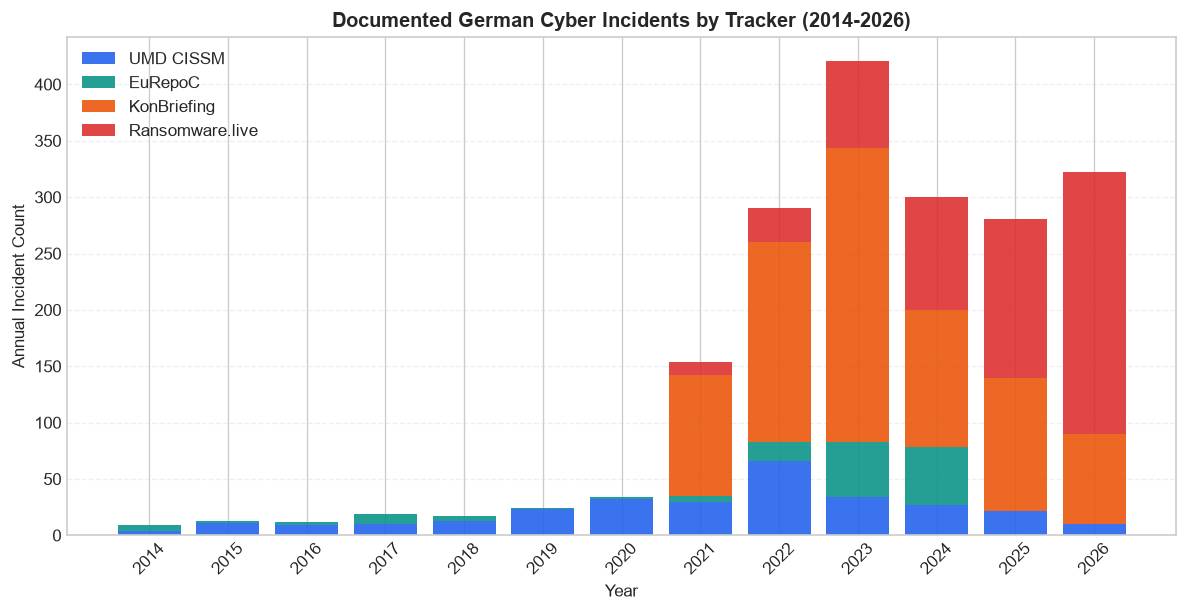

In [4]:
# Extract annual distributions across the 4 sources
umd_years = pd.to_datetime(umd_de["event_date"], errors="coerce").dt.year
eur_years = pd.to_datetime(eurepoc_de["start_date"], dayfirst=True, format="mixed", errors="coerce").dt.year
kb_years = pd.to_datetime(kb_enriched["date_raw"].astype(str).str.replace("?", "", regex=False).str.strip(), format="mixed", errors="coerce").dt.year

# Use published_date or discovered_date for Ransomware.live
rw_dates = pd.to_datetime(rw_de["published_date"].fillna(rw_de["discovered_date"]), errors="coerce")
rw_years = rw_dates.dt.year

years_range = np.arange(2014, 2027)
u_cnt = [int((umd_years == y).sum()) for y in years_range]
e_cnt = [int((eur_years == y).sum()) for y in years_range]
k_cnt = [int((kb_years == y).sum()) for y in years_range]
r_cnt = [int((rw_years == y).sum()) for y in years_range]

fig, ax = plt.subplots(figsize=(10, 5.2))

# Stacked annual incident volume by tracking source
ax.bar(years_range, u_cnt, label="UMD CISSM", color="#2563eb", alpha=0.9)
ax.bar(years_range, e_cnt, bottom=u_cnt, label="EuRepoC", color="#0d9488", alpha=0.9)
ax.bar(years_range, k_cnt, bottom=np.array(u_cnt)+np.array(e_cnt), label="KonBriefing", color="#ea580c", alpha=0.9)
ax.bar(years_range, r_cnt, bottom=np.array(u_cnt)+np.array(e_cnt)+np.array(k_cnt), label="Ransomware.live", color="#dc2626", alpha=0.85)
ax.set_title("Documented German Cyber Incidents by Tracker (2014-2026)", fontweight="bold")
ax.set_xlabel("Year")
ax.set_ylabel("Annual Incident Count")
ax.set_xticks(years_range)
ax.set_xticklabels([str(y) for y in years_range], rotation=45)
ax.legend(loc="upper left")
ax.grid(axis="y", linestyle="--", alpha=0.3)

plt.tight_layout()
plt.show()


---

## 4. Diagnosing Raw Taxonomies, Sentinel Traps & Encoding Quirks

Before writing harmonization code, we must inspect and document the exact data pitfalls uncovered during our empirical audit:

1. **KonBriefing Misplaced Entities**: In the original unparsed table, over 121 rows placed federal states (`Baden-WUrttemberg`) or cities (`DUsseldorf`) in `victim_organization`, while the real organization (`TAKKT AG`, `Badisches Landesmuseum`, `Targobank`, `GEZE`) was buried at the end of `keywords`.
2. **EuRepoC Non-State-Group Attribution Bug**: Naive substring search for `"state"` matches `"Non-state-group"`, erroneously turning hacktivists and criminals into state-sponsored APTs.
3. **CSV String Sentinel Traps**: In Pandas, `"None"` strings in CSV files are parsed as `NaN` by default, corrupting `functional_impact` (`"None"` $\to$ `NaN`) and `data_breach_scope`. Furthermore, EuRepoC codes missing financial damages as `0` (`economic_impact_value == 0`), which distorts economic loss averages unless converted to `np.nan`.
4. **Sector and Attack Keyword Collisions**:
   - NAICS `"Other Services (except Public Administration)"` falsely matched `"public administration"`.
   - The token `"conti"` (Conti ransomware) falsely matched words like `"continued"` and the German automotive company `"Continental"`.
   - Free-text CVE strings (`"CVE-2023-..."`) were falsely flagged as zero-days even when describing routine N-day patch delays.
5. **Multi-Encoded UTF-8 Mojibake**: Windows Latin-1 CSV exports produced multi-byte corruption (e.g. `Baden-WÃ¼rttemberg`, `DÃ¼sseldorf`, `UniversitÃ¤t`).


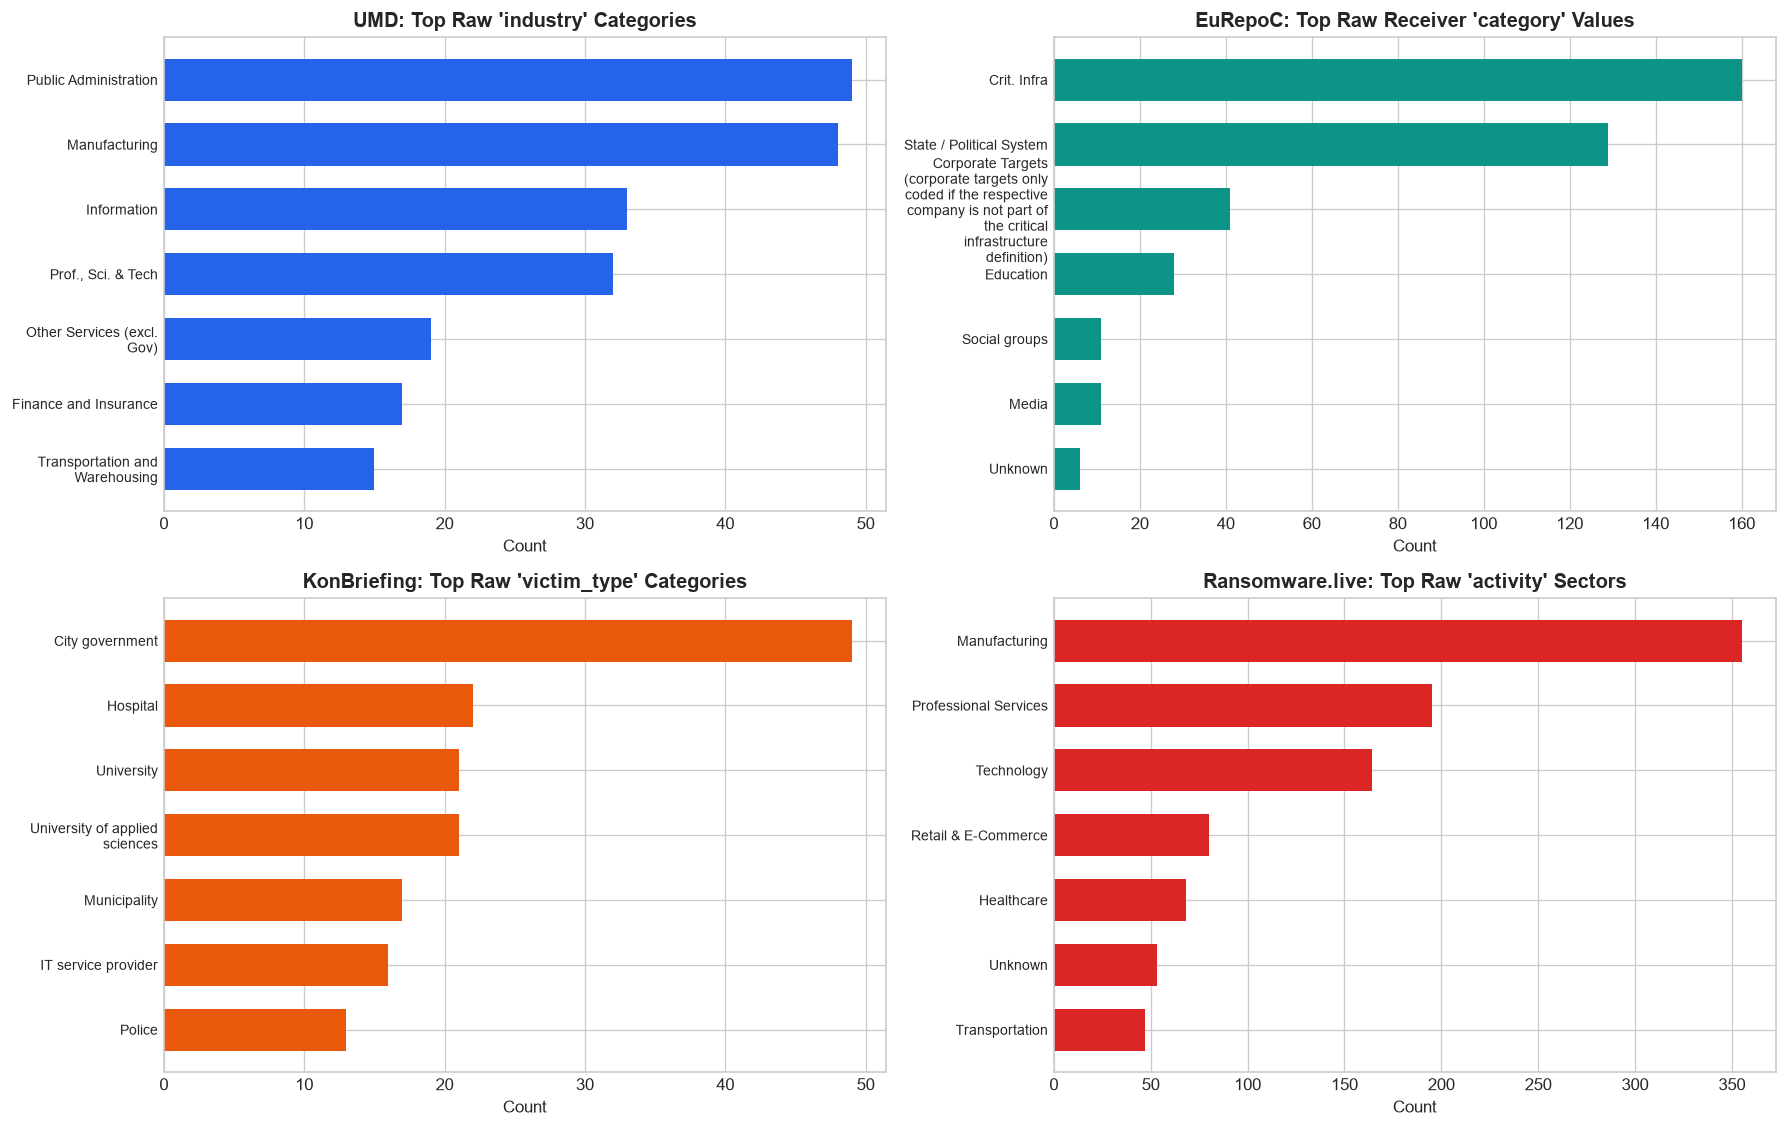

In [5]:
# Diagnostic Plot 4.1: Raw Sector Distributions Across Sources
def format_axis_label(text, width=24):
    import textwrap
    s = str(text).strip()
    s = s.replace("State institutions / political system", "State / Political System")
    s = s.replace("Critical infrastructure", "Crit. Infra")
    s = s.replace("Professional, Scientific, and Technical Services", "Prof., Sci. & Tech")
    s = s.replace("Other Services (except Public Administration)", "Other Services (excl. Gov)")
    return "\n".join(textwrap.wrap(s, width=width))

fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))

# 1. UMD raw industries
u_top = umd_de["industry"].fillna("Missing").value_counts().head(7)
axes[0, 0].barh(range(len(u_top)), u_top.values, color="#2563eb", height=0.65)
axes[0, 0].set_yticks(range(len(u_top)))
axes[0, 0].set_yticklabels([format_axis_label(x) for x in u_top.index], fontsize=8.5)
axes[0, 0].invert_yaxis()
axes[0, 0].set_title("UMD: Top Raw 'industry' Categories", fontweight="bold")
axes[0, 0].set_xlabel("Count")

# 2. EuRepoC raw receiver categories
e_top = eurepoc_receiver[eurepoc_receiver["country"].astype(str).str.contains("Germany", case=False, na=False)]["category"].value_counts().head(7)
axes[0, 1].barh(range(len(e_top)), e_top.values, color="#0d9488", height=0.65)
axes[0, 1].set_yticks(range(len(e_top)))
axes[0, 1].set_yticklabels([format_axis_label(x) for x in e_top.index], fontsize=8.5)
axes[0, 1].invert_yaxis()
axes[0, 1].set_title("EuRepoC: Top Raw Receiver 'category' Values", fontweight="bold")
axes[0, 1].set_xlabel("Count")

# 3. KonBriefing raw victim types
k_top = kb_enriched["victim_type"].fillna("Missing").value_counts().head(7)
axes[1, 0].barh(range(len(k_top)), k_top.values, color="#ea580c", height=0.65)
axes[1, 0].set_yticks(range(len(k_top)))
axes[1, 0].set_yticklabels([format_axis_label(x) for x in k_top.index], fontsize=8.5)
axes[1, 0].invert_yaxis()
axes[1, 0].set_title("KonBriefing: Top Raw 'victim_type' Categories", fontweight="bold")
axes[1, 0].set_xlabel("Count")

# 4. Ransomware.live raw activity sectors
r_top = rw_de["activity"].replace({"Not Found": "Unknown"}).value_counts().head(7)
axes[1, 1].barh(range(len(r_top)), r_top.values, color="#dc2626", height=0.65)
axes[1, 1].set_yticks(range(len(r_top)))
axes[1, 1].set_yticklabels([format_axis_label(x) for x in r_top.index], fontsize=8.5)
axes[1, 1].invert_yaxis()
axes[1, 1].set_title("Ransomware.live: Top Raw 'activity' Sectors", fontweight="bold")
axes[1, 1].set_xlabel("Count")

plt.tight_layout()
plt.show()


---

## 5. Harmonization, Entity Recovery, Geocoding & Completeness Gate

### 5.1 The 10 Harmonized Sectors
We harmonize all sector descriptions into **10 mutually exclusive sectors** aligned with European NACE Rev. 2 / Destatis classifications:
1. `Public Administration & Government` (NACE `O`): Municipalities, ministries, police, courts, federal agencies.
2. `Healthcare` (NACE `Q`): Hospitals (*Kliniken*), medical centers, pharma wholesalers, care services.
3. `Education & Research` (NACE `P` + `M72`): Universities, colleges, Fraunhofer/Max-Planck institutes, schools.
4. `Manufacturing & Industry` (NACE `B, C`): Automotive suppliers, mechanical engineering (*Maschinenbau*), chemicals, metals.
5. `Energy & Utilities` (NACE `D, E`): Municipal utilities (*Stadtwerke*), power grid, water, waste disposal.
6. `IT & Telecommunications` (NACE `J`): Software developers, cloud/hosting, data centers, telecoms.
7. `Finance & Insurance` (NACE `K`): Banks, savings banks (*Sparkassen*, *Volksbanken*), insurance, payment providers.
8. `Transportation & Logistics` (NACE `H`): Airports, railways, shipping, transit, warehousing.
9. `Retail, Trade & Services` (NACE `F, G, I, L, M, N`): Wholesale, e-commerce, hotels, construction, legal, consulting.
10. `Media, NGOs & Other` (NACE `A, R, S`): Broadcasters, publishers, cultural institutions, churches, parties, unions.

### 5.2 Minimum Data Completeness Gate
To prevent empty rows that provide zero analytical utility from cluttering the dataset, we enforce a strict **Completeness Gate**: any row that simultaneously lacks a named victim, a recognized sector, AND a classified attack type is pruned.


In [6]:
# Import verified harmonization and entity recovery engine
import importlib
sys.path[:] = [p for p in sys.path if "scratch" not in p.lower() and p != str(SCRIPTS_DIR)]
sys.path.insert(0, str(SCRIPTS_DIR))

for _mod_name in ("harmonize_helpers", "test_attack_enrichment", "test_eurepoc_builder", "dedup_2a_engine"):
    if _mod_name in sys.modules:
        importlib.reload(sys.modules[_mod_name])

from harmonize_helpers import (
    fix_text_all,
    extract_bundesland,
    resolve_umd_sector,
    resolve_eurepoc_receiver_row_sector,
    classify_sector_by_text,
    KRITIS_SECTORS,
    clean_victim_name,
    clean_description,
)
from test_attack_enrichment import extract_ransomware_family, standardize_attack_type
from test_eurepoc_builder import parse_eurepoc_date, recover_eurepoc_victim, standardize_actor_type
from dedup_2a_engine import extract_victim_match_keys, names_match, SOURCE_RANK

print("Harmonization and enrichment engine initialized successfully.")


Harmonization and enrichment engine initialized successfully.


In [7]:
# Load and standardize all 4 sources using our tested modules
import importlib
import build_and_verify_all
importlib.reload(build_and_verify_all)
build_and_verify_all.RAW_DIR = RAW_DIR
build_and_verify_all.PREPARED_DIR = PREPARED_DIR
from build_and_verify_all import load_umd, load_eurepoc, load_konbriefing, load_ransomware_live, deduplicate_incidents

df_umd = load_umd()
df_eur = load_eurepoc()
df_kb = load_konbriefing()
df_rw = load_ransomware_live()

# Combine into master unmerged dataframe
all_raw = pd.concat([df_eur, df_umd, df_rw, df_kb], ignore_index=True)
all_raw["date"] = pd.to_datetime(all_raw["date"], errors="coerce")
try:
    all_raw["date"] = all_raw["date"].dt.tz_localize(None)
except TypeError:
    pass

# Precompute victim match keys for fuzzy deduplication
all_raw["match_keys"] = all_raw["victim_name"].apply(extract_victim_match_keys)
all_raw["has_valid_date"] = all_raw["date"].notna()
all_raw = all_raw.sort_values(by=["has_valid_date", "date"], ascending=[False, True]).reset_index(drop=True)

# Apply Minimum Completeness Gate: drop rows where victim_name, sector, and attack_type are all NaN
valid_mask = ~(
    all_raw["victim_name"].isna()
    & all_raw["sector"].isna()
    & all_raw["attack_type"].isna()
)
all_raw = all_raw[valid_mask].reset_index(drop=True)

print(f"Total raw incidents across 4 trackers: {len(df_umd) + len(df_eur) + len(df_kb) + len(df_rw)}")
print(f"Total records passing Completeness Gate: {len(all_raw)}")


Loading UMD CISSM...


UMD processed: 291 rows
Loading EuRepoC v1.3...


EuRepoC processed: 171 rows
Loading KonBriefing Germany Enriched...


KonBriefing processed: 865 rows
Loading Ransomware.live Germany...


Ransomware.live processed: 1170 rows
Total raw incidents across 4 trackers: 2497
Total records passing Completeness Gate: 2481


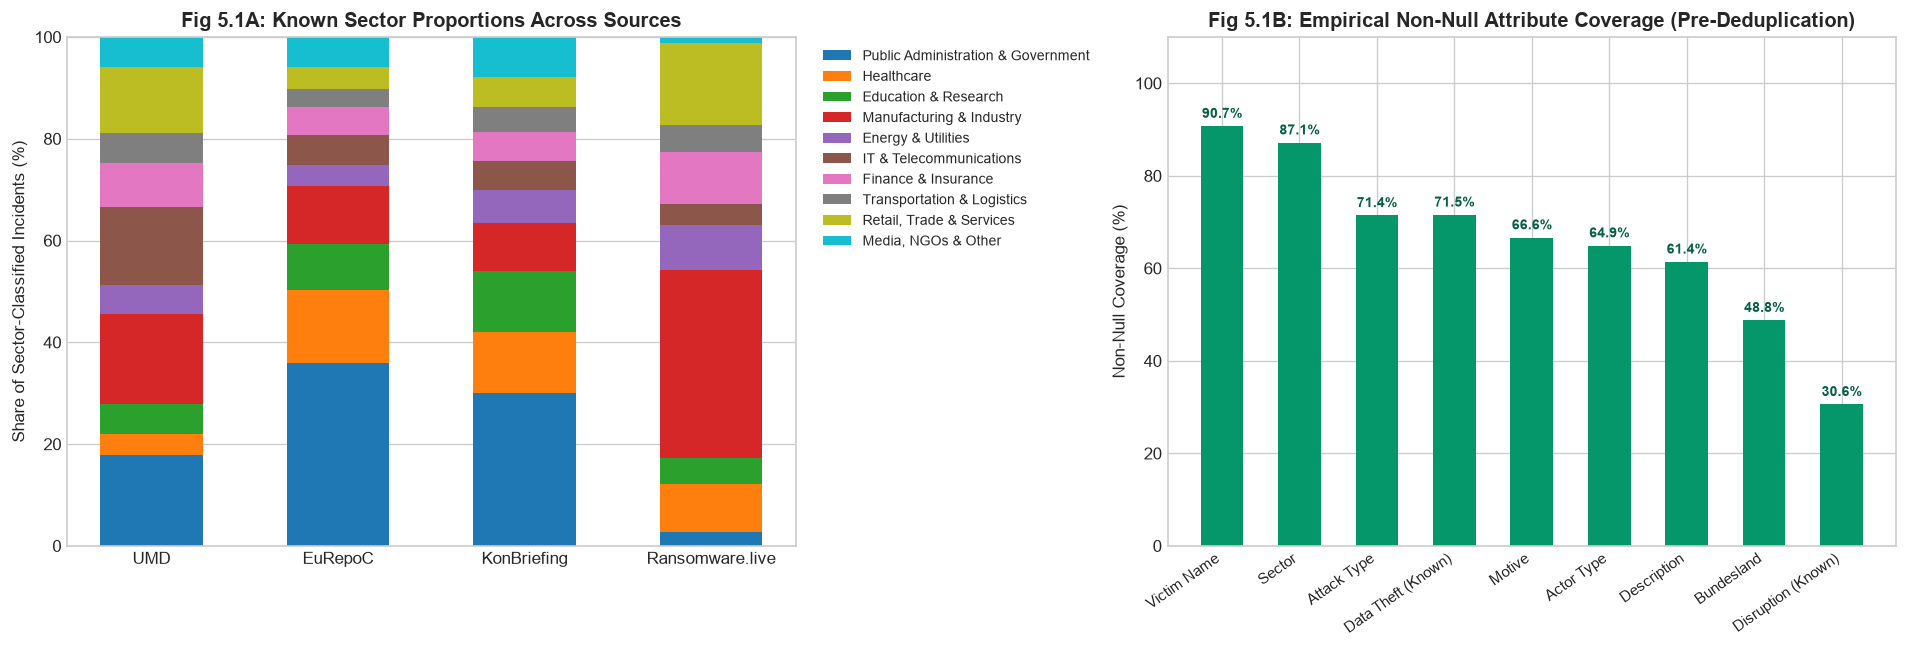

In [8]:
# Diagnostic Plot 5.1: Harmonized 10-Sector Distributions & Attribute Coverage by Source
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

# 1. 100% Stacked bar chart of known sector composition across sources
sector_names = [
    "Public Administration & Government", "Healthcare", "Education & Research",
    "Manufacturing & Industry", "Energy & Utilities", "IT & Telecommunications",
    "Finance & Insurance", "Transportation & Logistics", "Retail, Trade & Services",
    "Media, NGOs & Other"
]

src_labels = ["UMD", "EuRepoC", "KonBriefing", "Ransomware.live"]
src_dfs = [df_umd, df_eur, df_kb, df_rw]
sector_dist = pd.DataFrame(index=sector_names)

for lbl, sdf in zip(src_labels, src_dfs):
    vc = sdf["sector"].dropna().value_counts()
    sector_dist[lbl] = [vc.get(sec, 0) for sec in sector_names]

sector_dist_pct = sector_dist.div(sector_dist.sum(axis=0), axis=1) * 100
colors = plt.cm.tab10(np.linspace(0, 1, len(sector_names)))
bottoms = np.zeros(len(src_labels))

for i, sec in enumerate(sector_names):
    vals = sector_dist_pct.loc[sec].values
    axes[0].bar(src_labels, vals, bottom=bottoms, label=sec, color=colors[i], width=0.55)
    bottoms += vals

axes[0].set_title("Fig 5.1A: Known Sector Proportions Across Sources", fontweight="bold")
axes[0].set_ylabel("Share of Sector-Classified Incidents (%)")
axes[0].set_ylim(0, 100)
axes[0].legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8.5)

# 2. Honest Non-Null Attribute Coverage in Combined Unmerged Records (all_raw)
attrs = ["Victim Name", "Sector", "Attack Type", "Data Theft (Known)", "Motive", "Actor Type", "Description", "Bundesland", "Disruption (Known)"]
attr_cols = ["victim_name", "sector", "attack_type", "has_data_theft", "motive", "actor_type", "description", "bundesland", "has_disruption"]
fill_rates = [all_raw[c].notna().mean() * 100 for c in attr_cols]

x_idx = np.arange(len(attrs))
axes[1].bar(x_idx, fill_rates, width=0.55, color="#059669")
axes[1].set_xticks(x_idx)
axes[1].set_xticklabels(attrs, rotation=35, ha="right", fontsize=9)
axes[1].set_title("Fig 5.1B: Empirical Non-Null Attribute Coverage (Pre-Deduplication)", fontweight="bold")
axes[1].set_ylabel("Non-Null Coverage (%)")
axes[1].set_ylim(0, 110)

for i, v in enumerate(fill_rates):
    axes[1].text(i, v + 1.8, f"{v:.1f}%", ha="center", fontsize=8.5, fontweight="bold", color="#065f46")

plt.tight_layout()
plt.show()


---

## 6. Deduplication & Generating Dataset 1 (`germany_large_incidents.csv`)

### 6.1 Deduplication Methodology (`1 row = 1 distinct incident`)
When prominent incidents occur (e.g. *Südwestfalen-IT*, *Rheinmetall*, *Continental*, *MediaMarktSaturn*), multiple trackers report the event with differing timestamps and varying spellings.

To merge records accurately while preventing false merges:
1. **Dynamic Time Windows**:
   - Exact Day $\leftrightarrow$ Exact Day: $\pm 18$ days.
   - Leak-Site Timestamp (Ransomware.live posting lag) or Month-Only: $\pm 31$ days.
   - Year-Only: Strict exact entity match within the same calendar year.
2. **Dual-Transliteration Fuzzy Matching**:
   - Generates both German-transliterated (`ä` $\to$ `ae`, `ö` $\to$ `oe`, `ü` $\to$ `ue`) and ASCII-stripped (`ä` $\to$ `a`, `ö` $\to$ `o`, `ü` $\to$ `u`) keys.
   - Handles international press transliterations (e.g. *Eberspacher* vs *Eberspächer*, *Larssen* vs *Lürssen*).
   - Member-wise list matching for multi-victim campaigns.
3. **Attribute Precedence (`SOURCE_RANK`) & Three-State Consequence Merging**:
   - `EuRepoC` (Rank 1) $\to$ `UMD` (Rank 2) $\to$ `Ransomware.live` (Rank 3) $\to$ `KonBriefing` (Rank 4).
   - Consequence booleans (`has_disruption`, `has_data_theft`) preserve true 3-state semantics: `True` if any corroborating source confirmed the effect, `False` if confirmed absent (`False`) and no source reported `True`, and `pd.NA` (`NaN`) when neither presence nor absence was confirmed.


In [9]:
# Execute cross-source entity deduplication and save Dataset 1 (19 well-supported columns)
large_incidents = deduplicate_incidents(all_raw)

out_incidents_path = PREPARED_DIR / "germany_large_incidents.csv"
large_incidents.to_csv(out_incidents_path, index=False, encoding="utf-8")

print(f"Total records passing Completeness Gate: {len(all_raw):,}")
print(f"Final deduplicated incidents (Dataset 1): {len(large_incidents):,} rows x {len(large_incidents.columns)} columns")
print(f"Multi-source corroborated attacks:       {(large_incidents['num_sources'] > 1).sum():,}")
print(f"Saved Dataset 1 to: {out_incidents_path}")


Total records passing Completeness Gate: 2,481
Final deduplicated incidents (Dataset 1): 2,323 rows x 19 columns
Multi-source corroborated attacks:       129
Saved Dataset 1 to: D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\data\prepared\germany_large_incidents.csv


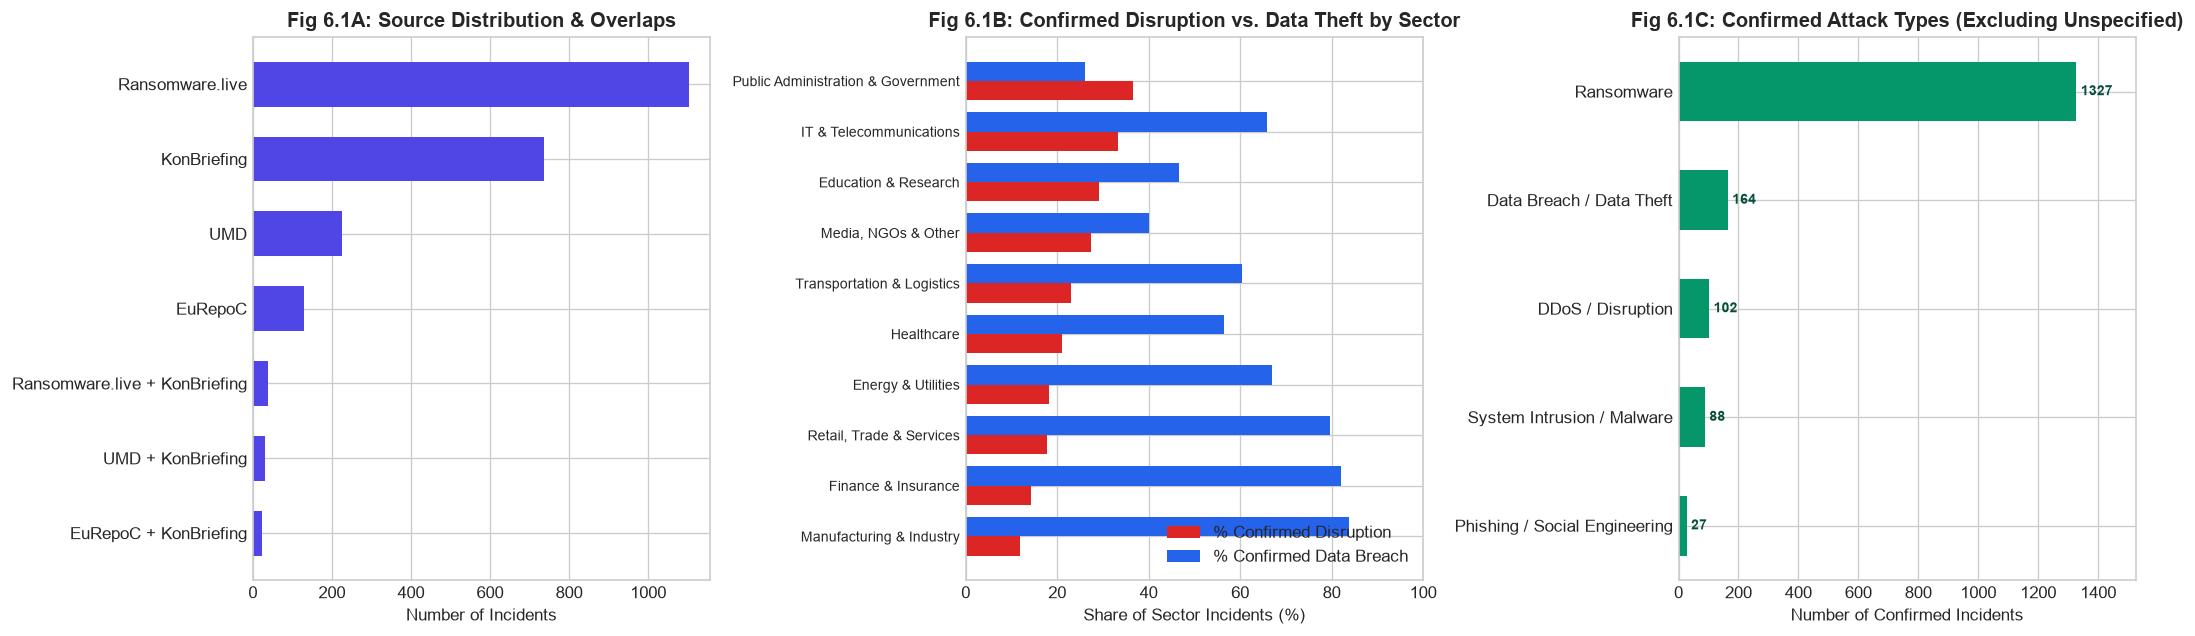

In [10]:
# Diagnostic Plot 6.1: Corroboration, Sectoral Consequences & Attack Types in Dataset 1
fig, axes = plt.subplots(1, 3, figsize=(18, 5.4))

# 1. Source overlap distribution
src_counts = large_incidents["source"].value_counts().head(7)
axes[0].barh(src_counts.index, src_counts.values, color="#4f46e5", height=0.6)
axes[0].invert_yaxis()
axes[0].set_title("Fig 6.1A: Source Distribution & Overlaps", fontweight="bold")
axes[0].set_xlabel("Number of Incidents")

# 2. Confirmed Disruption vs. Confirmed Data Theft rates by Sector (% of all sector incidents)
sec_conseq = (
    large_incidents.dropna(subset=["sector"])
    .groupby("sector")
    .agg(
        disruption_rate=("has_disruption", lambda s: (s == True).mean() * 100),
        theft_rate=("has_data_theft", lambda s: (s == True).mean() * 100),
        count=("incident_id", "count"),
    )
    .sort_values("disruption_rate")
)

y_pos = np.arange(len(sec_conseq))
bar_h = 0.38
axes[1].barh(y_pos - bar_h/2, sec_conseq["disruption_rate"], height=bar_h, label="% Confirmed Disruption", color="#dc2626")
axes[1].barh(y_pos + bar_h/2, sec_conseq["theft_rate"], height=bar_h, label="% Confirmed Data Breach", color="#2563eb")
axes[1].set_yticks(y_pos)
axes[1].set_yticklabels(sec_conseq.index, fontsize=8.5)
axes[1].set_xlim(0, 100)
axes[1].set_title("Fig 6.1B: Confirmed Disruption vs. Data Theft by Sector", fontweight="bold")
axes[1].set_xlabel("Share of Sector Incidents (%)")
axes[1].legend(loc="lower right")

# 3. Confirmed Attack Types Distribution (excluding NaN)
att_counts = large_incidents["attack_type"].dropna().value_counts()
axes[2].barh(att_counts.index, att_counts.values, color="#059669", height=0.55)
axes[2].invert_yaxis()
axes[2].set_title("Fig 6.1C: Confirmed Attack Types (Excluding Unspecified)", fontweight="bold")
axes[2].set_xlabel("Number of Confirmed Incidents")

for i, v in enumerate(att_counts.values):
    axes[2].text(v + 15, i, str(v), va="center", fontsize=8.5, fontweight="bold", color="#064e3b")
axes[2].set_xlim(0, att_counts.max() * 1.15)

plt.tight_layout()
plt.show()


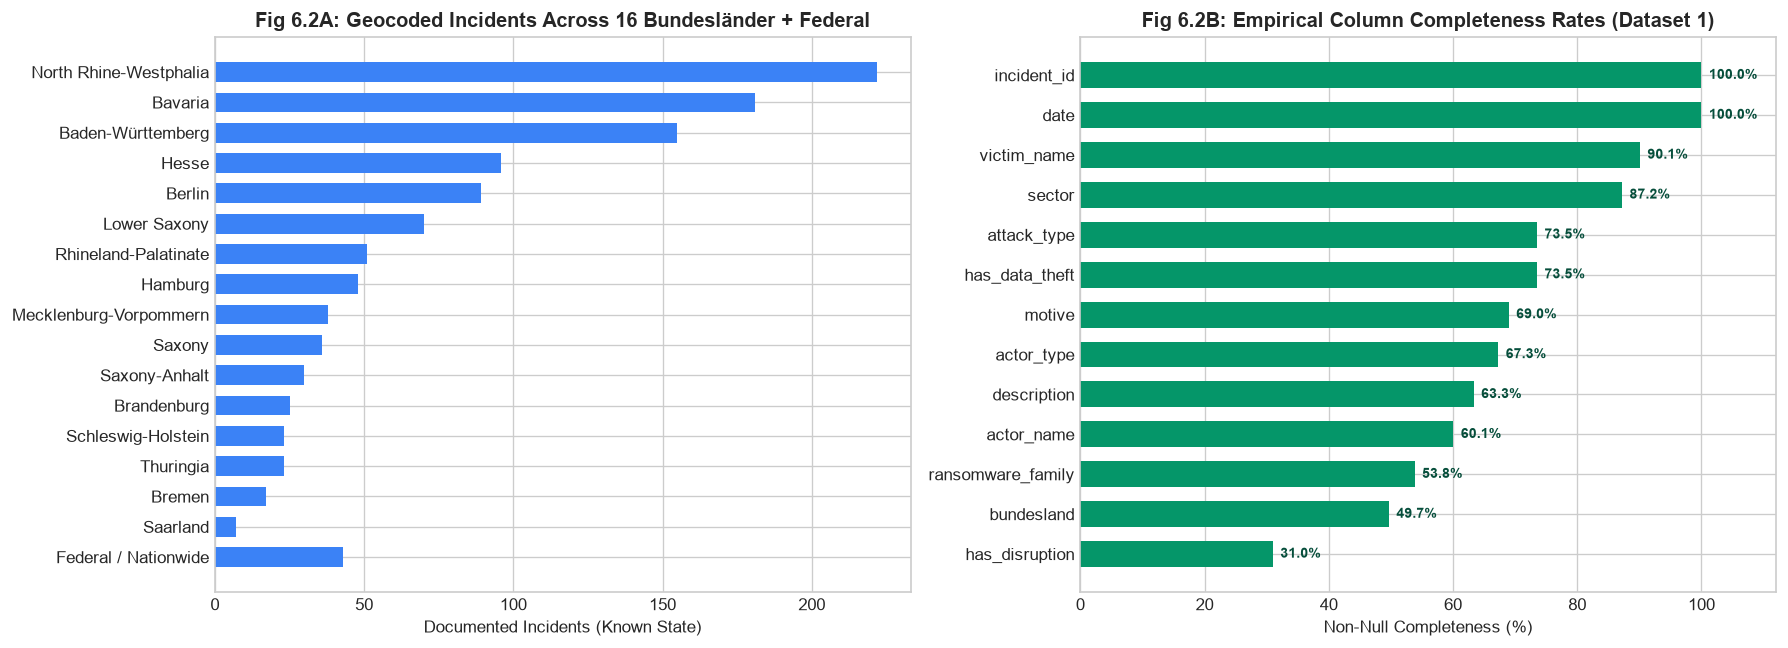

In [11]:
# Diagnostic Plot 6.2: Geographic Spread (16 Bundesländer) & Honest Column Completeness
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

# 1. Geographic distribution across German Federal States
states_order = [
    "North Rhine-Westphalia", "Bavaria", "Baden-Württemberg", "Hesse",
    "Berlin", "Lower Saxony", "Rhineland-Palatinate", "Hamburg",
    "Mecklenburg-Vorpommern", "Saxony", "Saxony-Anhalt", "Brandenburg",
    "Schleswig-Holstein", "Thuringia", "Bremen", "Saarland", "Federal / Nationwide"
]
state_counts = large_incidents[large_incidents["bundesland"].isin(states_order)]["bundesland"].value_counts().reindex(states_order).fillna(0)

axes[0].barh(state_counts.index, state_counts.values, color="#3b82f6", height=0.65)
axes[0].invert_yaxis()
axes[0].set_title("Fig 6.2A: Geocoded Incidents Across 16 Bundesländer + Federal", fontweight="bold")
axes[0].set_xlabel("Documented Incidents (Known State)")

# 2. Honest Non-Null Column Completeness Audit (Dataset 1)
audit_cols = [
    "incident_id", "date", "victim_name", "sector", "attack_type",
    "has_data_theft", "motive", "actor_type", "description",
    "actor_name", "ransomware_family", "bundesland", "has_disruption"
]
col_fill_rates = [large_incidents[c].notna().mean() * 100 for c in audit_cols]

axes[1].barh(audit_cols, col_fill_rates, color="#059669", height=0.65)
axes[1].invert_yaxis()
axes[1].set_xlim(0, 112)
axes[1].set_title("Fig 6.2B: Empirical Column Completeness Rates (Dataset 1)", fontweight="bold")
axes[1].set_xlabel("Non-Null Completeness (%)")

for i, v in enumerate(col_fill_rates):
    axes[1].text(v + 1.2, i, f"{v:.1f}%", va="center", fontsize=8.5, fontweight="bold", color="#064e3b")

plt.tight_layout()
plt.show()


---

## 7. Compiling Dataset 2: National Yearly Overview (`germany_yearly_overview.csv`, 2014–2026)

### 7.1 Methodological Integration
While `germany_large_incidents.csv` documents qualitative targeted attacks, **hundreds of thousands of smaller routine cybercrimes** are only recorded in annual police statistics (BKA) and business surveys (Bitkom).

In this section, we compile **`germany_yearly_overview.csv`** (`13 rows × 35 columns`, 1 row = 1 calendar year) by merging:
1. **World Bank Macroeconomic Indicators**: Nominal & real EUR GDP, GDP per capita, broadband penetration, and R&D spending.
2. **BKA *Bundeslagebild Cybercrime***: Domestic cybercrimes (*Inlandstaten*), crimes committed from abroad (*Auslandstaten*), and police solve rates. (Notice: `from_abroad` was introduced systematically in 2021; pre-2021 values are retained as `NaN` rather than distorted with `fillna(0)`).
3. **Bitkom *Wirtschaftsschutz***: Total corporate damages and direct cyberattack damage in € billions, plus cyber damage as a `% of EUR GDP`.
4. **BSI & BfDI Federal Series**: Mandatory KRITIS incident reports (§ 8b BSIG) and GDPR personal data breach notifications.
5. **Aggregated Incident Dynamics from Dataset 1**: Annual counts of large attacks, ransomware events, state-sponsored campaigns, disruptive events, and source-stratified counts.


In [12]:
# Load raw macroeconomic and national cybercrime reference tables
wb_yearly = pd.read_csv(RAW_DIR / "world_bank_germany.csv")
official_yearly = pd.read_csv(RAW_DIR / "bka_bitkom_eurostat_yearly.csv")

# Filter incidents strictly within the 2014-2026 analytical horizon
inc_de_horizon = large_incidents[(large_incidents["year"] >= 2014) & (large_incidents["year"] <= 2026)].copy()

# Annual incident aggregations
annual_agg = (
    inc_de_horizon.groupby("year")
    .agg(
        documented_large_incidents=("incident_id", "count"),
        documented_ransomware_incidents=("attack_type", lambda s: (s == "Ransomware").sum()),
        documented_state_sponsored_incidents=("actor_type", lambda s: (s == "State-Sponsored").sum()),
        documented_disruptive_incidents=("has_disruption", lambda s: (s == True).sum()),
        documented_data_theft_incidents=("has_data_theft", lambda s: (s == True).sum()),
        documented_kritis_incidents=("is_kritis_sector", lambda s: (s == True).sum()),
        incidents_eurepoc=("source", lambda s: s.str.contains("EuRepoC").sum()),
        incidents_umd=("source", lambda s: s.str.contains("UMD").sum()),
        incidents_ransomware_live=("source", lambda s: s.str.contains("Ransomware.live").sum()),
        incidents_konbriefing=("source", lambda s: s.str.contains("KonBriefing").sum()),
    )
    .reindex(range(2014, 2027), fill_value=0)
    .reset_index()
)

# Merge macroeconomic baseline, national police/survey data, and incident aggregations
yearly_overview = (
    wb_yearly
    .merge(official_yearly, on="year", how="left")
    .merge(annual_agg, on="year", how="left")
)

# Safe total BKA calculation: preserve NaN pre-2021 for from_abroad rather than distorting with 0
yearly_overview["bka_cybercrime_total_known"] = yearly_overview.apply(
    lambda r: (r["bka_cybercrime_domestic"] + r["bka_cybercrime_from_abroad"])
    if pd.notna(r["bka_cybercrime_from_abroad"])
    else r["bka_cybercrime_domestic"],
    axis=1,
)

# Bitkom cyber damage as percentage of German EUR GDP (macro loss ratio)
yearly_overview["bitkom_cyber_damage_pct_gdp"] = (
    yearly_overview["bitkom_cyber_damage_eur_bn"] / yearly_overview["gdp_billion_eur"] * 100
).round(3)

out_yearly_path = PREPARED_DIR / "germany_yearly_overview.csv"
yearly_overview.to_csv(out_yearly_path, index=False, encoding="utf-8")

print(f"Dataset 2 Saved: {yearly_overview.shape[0]} rows (2014–2026) x {yearly_overview.shape[1]} columns to {out_yearly_path}")
display(yearly_overview[["year", "gdp_billion_eur", "bka_cybercrime_domestic", "bka_cybercrime_from_abroad", "bitkom_cyber_damage_eur_bn", "bitkom_cyber_damage_pct_gdp", "bsi_kritis_incidents_total", "documented_large_incidents", "documented_ransomware_incidents"]])


Dataset 2 Saved: 13 rows (2014–2026) x 35 columns to D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\data\prepared\germany_yearly_overview.csv


,year,gdp_billion_eur,bka_cybercrime_domestic,bka_cybercrime_from_abroad,bitkom_cyber_damage_eur_bn,bitkom_cyber_damage_pct_gdp,bsi_kritis_incidents_total,documented_large_incidents,documented_ransomware_incidents
0,2014,2984.47,49925.0,NaN,NaN,NaN,NaN,9,0
1,2015,3087.03,45793.0,NaN,NaN,NaN,NaN,12,0
2,2016,3195.21,82649.0,NaN,NaN,NaN,NaN,11,0
3,2017,3333.11,85960.0,NaN,NaN,NaN,34.0,19,5
4,2018,3434.03,87106.0,NaN,NaN,NaN,145.0,18,1
5,2019,3537.28,100514.0,NaN,61.7,1.744,252.0,24,1
6,2020,3450.72,108474.0,NaN,145.0,4.202,419.0,35,12
7,2021,3682.34,146363.0,101000.0,152.0,4.128,385.0,140,36
8,2022,3989.39,136865.0,109500.0,137.8,3.454,452.0,272,86
9,2023,4219.31,134407.0,140285.0,148.2,3.512,490.0,421,165


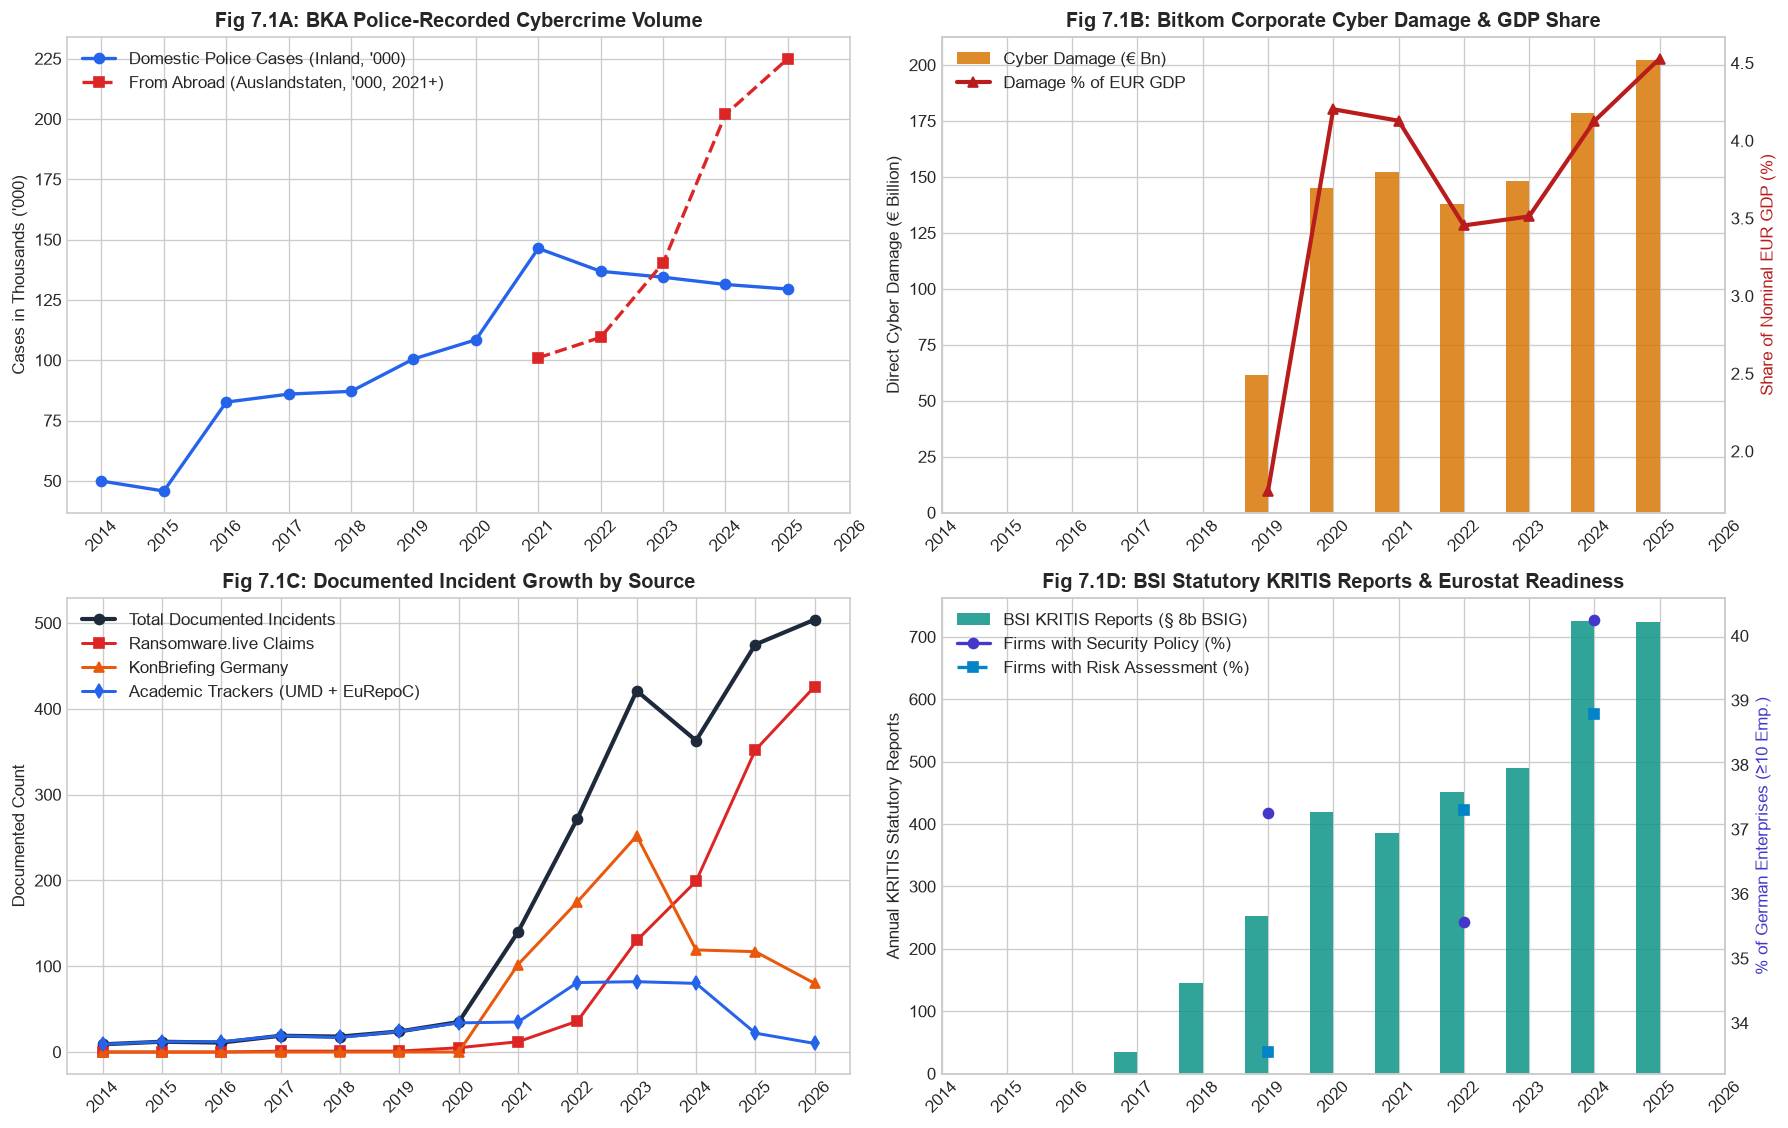

In [13]:
# Diagnostic Plot 7.1: National Cybersecurity & Macro Dashboard (2014–2026)
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))
x = yearly_overview["year"]

# 1. BKA Cybercrime: Domestic vs Abroad
axes[0, 0].plot(x, yearly_overview["bka_cybercrime_domestic"] / 1000, marker="o", color="#2563eb", linewidth=2, label="Domestic Police Cases (Inland, '000)")
axes[0, 0].plot(x, yearly_overview["bka_cybercrime_from_abroad"] / 1000, marker="s", color="#dc2626", linewidth=2, linestyle="--", label="From Abroad (Auslandstaten, '000, 2021+)")
axes[0, 0].set_title("Fig 7.1A: BKA Police-Recorded Cybercrime Volume", fontweight="bold")
axes[0, 0].set_ylabel("Cases in Thousands ('000)")
axes[0, 0].set_xticks(x)
axes[0, 0].set_xticklabels([str(y) for y in x], rotation=45)
axes[0, 0].legend()

# 2. Bitkom Damages & % of German EUR GDP
ax2_twin = axes[0, 1].twinx()
p1 = axes[0, 1].bar(x - 0.18, yearly_overview["bitkom_cyber_damage_eur_bn"], width=0.36, color="#d97706", alpha=0.85, label="Cyber Damage (€ Bn)")
p2 = ax2_twin.plot(x, yearly_overview["bitkom_cyber_damage_pct_gdp"], color="#b91c1c", marker="^", linewidth=2.5, label="Damage % of EUR GDP")
axes[0, 1].set_title("Fig 7.1B: Bitkom Corporate Cyber Damage & GDP Share", fontweight="bold")
axes[0, 1].set_ylabel("Direct Cyber Damage (€ Billion)")
ax2_twin.set_ylabel("Share of Nominal EUR GDP (%)", color="#b91c1c")
ax2_twin.grid(False)
axes[0, 1].set_xticks(x)
axes[0, 1].set_xticklabels([str(y) for y in x], rotation=45)

# Combined legend for twin axes
lines1, labels1 = axes[0, 1].get_legend_handles_labels()
lines2, labels2 = ax2_twin.get_legend_handles_labels()
axes[0, 1].legend(lines1 + lines2, labels1 + labels2, loc="upper left")

# 3. Source-stratified documented incidents trajectory
axes[1, 0].plot(x, yearly_overview["documented_large_incidents"], marker="o", color="#1e293b", linewidth=2.5, label="Total Documented Incidents")
axes[1, 0].plot(x, yearly_overview["incidents_ransomware_live"], marker="s", color="#dc2626", linewidth=1.8, label="Ransomware.live Claims")
axes[1, 0].plot(x, yearly_overview["incidents_konbriefing"], marker="^", color="#ea580c", linewidth=1.8, label="KonBriefing Germany")
axes[1, 0].plot(x, yearly_overview["incidents_umd"] + yearly_overview["incidents_eurepoc"], marker="d", color="#2563eb", linewidth=1.8, label="Academic Trackers (UMD + EuRepoC)")
axes[1, 0].set_title("Fig 7.1C: Documented Incident Growth by Source", fontweight="bold")
axes[1, 0].set_ylabel("Documented Count")
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels([str(y) for y in x], rotation=45)
axes[1, 0].legend()

# 4. BSI Mandatory KRITIS Incidents vs. Eurostat Corporate Preparedness
ax4_twin = axes[1, 1].twinx()
p3 = axes[1, 1].bar(x - 0.18, yearly_overview["bsi_kritis_incidents_total"], width=0.36, color="#0d9488", alpha=0.85, label="BSI KRITIS Reports (§ 8b BSIG)")
p4 = ax4_twin.plot(x, yearly_overview["eurostat_firms_security_policy_pct"], color="#4338ca", marker="o", linewidth=2, label="Firms with Security Policy (%)")
ax4_twin.plot(x, yearly_overview["eurostat_firms_risk_assessment_pct"], color="#0284c7", marker="s", linewidth=2, linestyle="--", label="Firms with Risk Assessment (%)")
axes[1, 1].set_title("Fig 7.1D: BSI Statutory KRITIS Reports & Eurostat Readiness", fontweight="bold")
axes[1, 1].set_ylabel("Annual KRITIS Statutory Reports")
ax4_twin.set_ylabel("% of German Enterprises (≥10 Emp.)", color="#4338ca")
ax4_twin.grid(False)
axes[1, 1].set_xticks(x)
axes[1, 1].set_xticklabels([str(y) for y in x], rotation=45)

lines3, labels3 = axes[1, 1].get_legend_handles_labels()
lines4, labels4 = ax4_twin.get_legend_handles_labels()
axes[1, 1].legend(lines3 + lines4, labels3 + labels4, loc="upper left")

plt.tight_layout()
plt.show()


---

## 8. Compiling Dataset 3: Sector-Year Balanced Panel (`germany_sector_year_panel.csv`, 130 rows)

### 8.1 Methodological Construction (`13 years × 10 sectors = 130 rows`)
For econometric analysis and Multi-Criteria Decision Modeling (DEXi / AHP), researchers need a structured panel dataset combining **incident counts and rates with official economic exposure denominators**:

1. **Balanced Panel Grid**: Exactly 13 years (`2014–2026`) $\times$ 10 harmonized sectors = **130 rows**.
2. **Economic Denominators (Eurostat & Destatis)**:
   - `sec_gva_eur_bn`: Sectoral Gross Value Added in € billions (`nama_10_a64`).
   - `sec_employment_thousands`: Sectoral workforce in thousands of persons (`nama_10_a64_e`).
   - `sec_active_enterprises`: Active enterprises in Germany from Business Demography (`bd_9bd_sz_cl_r2` & `bd_size`).
3. **Sectoral Cybersecurity Defense & Survey Base Rates**:
   - `sec_eurostat_incident_pct`: % of firms experiencing security incidents.
   - `sec_eurostat_security_policy_pct`: % of firms with formal ICT security policies.
   - `sec_eurostat_risk_assessment_pct`: % of firms conducting security risk assessments.
   - `sec_eurostat_cyber_insurance_pct`: % of firms holding cyber insurance.
4. **Normalized Exposure Rates**:
   - `incidents_per_10k_enterprises`: $\frac{\text{documented incidents}}{\text{sec\_active\_enterprises}} \times 10{,}000$.
   - `incidents_per_10bn_eur_gva`: $\frac{\text{documented incidents}}{\text{sec\_gva\_eur\_bn}} \times 10.0$.
5. **Strict Variable Namespacing**: National macroeconomic benchmarks are prefixed with `nat_` (`nat_gdp_billion_eur`, `nat_bka_cybercrime_domestic`, etc.) to explicitly prevent analysts from summing national figures 10 times across sectors!


In [14]:
# Load sectoral reference table
sector_base = pd.read_csv(RAW_DIR / "eurostat_destatis_sector_yearly.csv")

# Aggregate documented incidents by year and sector (among rows with a known sector)
inc_sec_yr = (
    inc_de_horizon.dropna(subset=["sector"])
    .groupby(["year", "sector"])
    .agg(
        documented_incidents=("incident_id", "count"),
        ransomware_incidents=("attack_type", lambda s: (s == "Ransomware").sum()),
        disruptive_incidents=("has_disruption", lambda s: (s == True).sum()),
        data_theft_incidents=("has_data_theft", lambda s: (s == True).sum()),
    )
    .reset_index()
)

# Merge onto the balanced panel grid
sector_panel = sector_base.merge(inc_sec_yr, on=["year", "sector"], how="left")
sector_panel["documented_incidents"] = sector_panel["documented_incidents"].fillna(0).astype(int)
sector_panel["ransomware_incidents"] = sector_panel["ransomware_incidents"].fillna(0).astype(int)
sector_panel["disruptive_incidents"] = sector_panel["disruptive_incidents"].fillna(0).astype(int)
sector_panel["data_theft_incidents"] = sector_panel["data_theft_incidents"].fillna(0).astype(int)

# Calculate exposure-normalized risk rates
sector_panel["incidents_per_10k_enterprises"] = np.where(
    sector_panel["sec_active_enterprises"] > 0,
    (sector_panel["documented_incidents"] / sector_panel["sec_active_enterprises"] * 10000).round(3),
    np.nan,
)
sector_panel["incidents_per_10bn_eur_gva"] = np.where(
    sector_panel["sec_gva_eur_bn"] > 0,
    (sector_panel["documented_incidents"] / sector_panel["sec_gva_eur_bn"] * 10.0).round(3),
    np.nan,
)

# Attach national benchmarks with 'nat_' prefix
nat_cols = yearly_overview[[
    "year", "gdp_billion_eur", "bka_cybercrime_domestic", "bka_cybercrime_from_abroad",
    "bitkom_total_damage_eur_bn", "bsi_kritis_incidents_total"
]].rename(columns={
    "gdp_billion_eur": "nat_gdp_billion_eur",
    "bka_cybercrime_domestic": "nat_bka_cybercrime_domestic",
    "bka_cybercrime_from_abroad": "nat_bka_cybercrime_from_abroad",
    "bitkom_total_damage_eur_bn": "nat_bitkom_damage_eur_bn",
    "bsi_kritis_incidents_total": "nat_bsi_kritis_incidents_total",
})

sector_panel = sector_panel.merge(nat_cols, on="year", how="left")

out_panel_path = PREPARED_DIR / "germany_sector_year_panel.csv"
sector_panel.to_csv(out_panel_path, index=False, encoding="utf-8")

print(f"Dataset 3 Saved: {sector_panel.shape[0]} rows (13 yrs x 10 sectors) x {sector_panel.shape[1]} columns to {out_panel_path}")
display(sector_panel[sector_panel["year"] == 2024][["year", "sector", "documented_incidents", "ransomware_incidents", "sec_gva_eur_bn", "sec_active_enterprises", "incidents_per_10k_enterprises", "incidents_per_10bn_eur_gva"]])


Dataset 3 Saved: 130 rows (13 yrs x 10 sectors) x 21 columns to D:\fakultet mrtvi\Modeli in Odločitveni Sistemi\Projekt\germany\data\prepared\germany_sector_year_panel.csv


,year,sector,documented_incidents,ransomware_incidents,sec_gva_eur_bn,sec_active_enterprises,incidents_per_10k_enterprises,incidents_per_10bn_eur_gva
100,2024,Public Administration & Government,51,8,249.965,NaN,NaN,2.040
101,2024,Healthcare,49,31,339.849,247473.0,1.980,1.442
102,2024,Education & Research,20,8,188.822,60608.0,3.300,1.059
103,2024,Manufacturing & Industry,65,48,799.037,199898.0,3.252,0.813
104,2024,Energy & Utilities,17,12,131.890,76226.0,2.230,1.289
105,2024,IT & Telecommunications,19,11,187.796,134400.0,1.414,1.012
106,2024,Finance & Insurance,22,20,152.074,75338.0,2.920,1.447
107,2024,Transportation & Logistics,12,7,186.052,100305.0,1.196,0.645
108,2024,"Retail, Trade & Services",26,20,1571.268,2080452.0,0.125,0.165
109,2024,"Media, NGOs & Other",17,2,163.181,266239.0,0.639,1.042


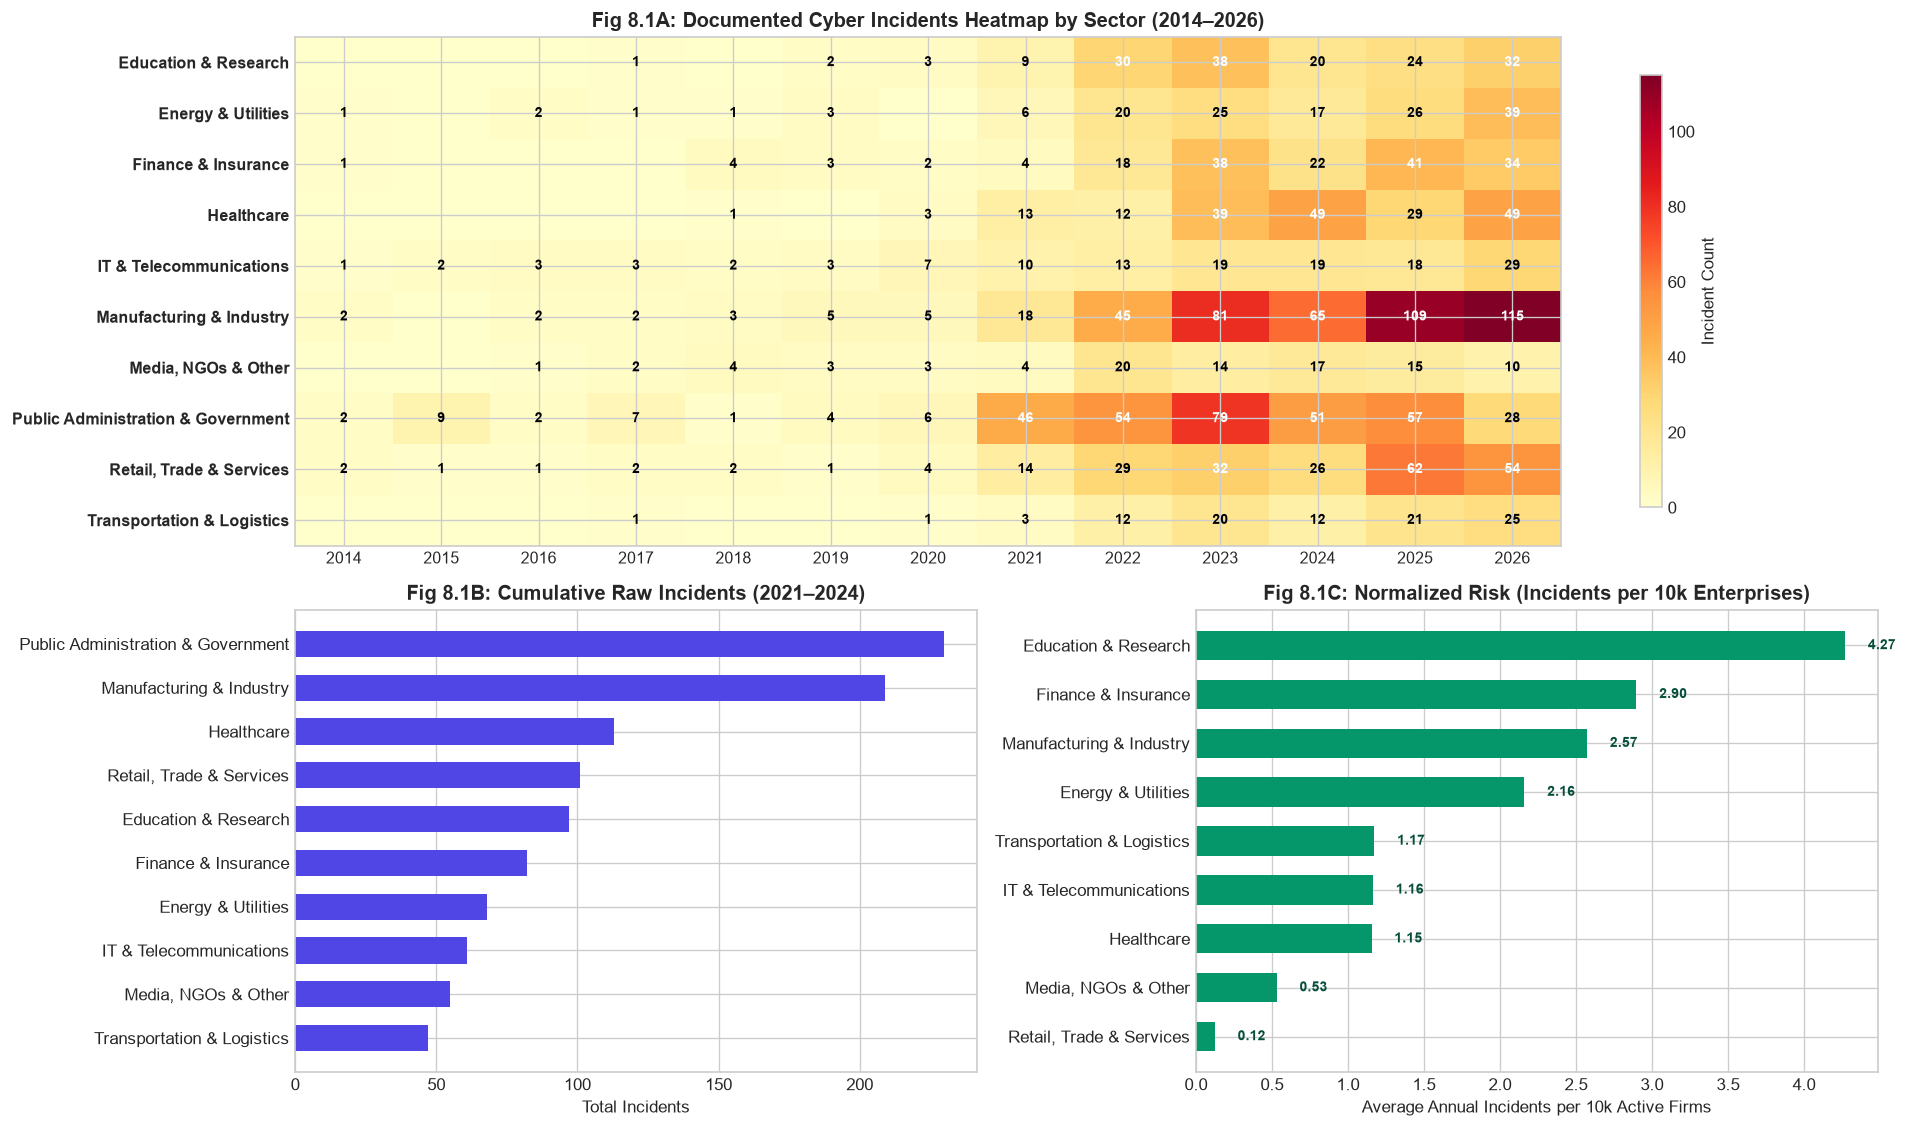

In [15]:
# Diagnostic Plot 8.1: Sectoral Heatmap and Exposure-Normalized Risk Rates
fig = plt.figure(figsize=(16, 9.5))
gs = fig.add_gridspec(2, 2, height_ratios=[1.1, 1.0])

# Top: Year x Sector Incident Heatmap
ax_heat = fig.add_subplot(gs[0, :])
pivot_inc = sector_panel.pivot(index="sector", columns="year", values="documented_incidents").fillna(0)

im_h = ax_heat.imshow(pivot_inc.values, cmap="YlOrRd", aspect="auto")
ax_heat.set_yticks(range(len(pivot_inc.index)))
ax_heat.set_yticklabels(pivot_inc.index, fontsize=9.5, fontweight="bold")
ax_heat.set_xticks(range(len(pivot_inc.columns)))
ax_heat.set_xticklabels([str(y) for y in pivot_inc.columns], fontsize=9.5)
ax_heat.set_title("Fig 8.1A: Documented Cyber Incidents Heatmap by Sector (2014–2026)", fontweight="bold")
fig.colorbar(im_h, ax=ax_heat, label="Incident Count", shrink=0.85)

for i in range(len(pivot_inc.index)):
    for j in range(len(pivot_inc.columns)):
        val = int(pivot_inc.values[i, j])
        if val > 0:
            c = "white" if val >= 30 else "black"
            ax_heat.text(j, i, str(val), ha="center", va="center", color=c, fontsize=8.5, fontweight="bold")

# Bottom Left: Cumulative Documented Incidents (2021-2024)
ax_raw = fig.add_subplot(gs[1, 0])
p_recent = sector_panel[(sector_panel["year"] >= 2021) & (sector_panel["year"] <= 2024)]
sec_sum = p_recent.groupby("sector")["documented_incidents"].sum().sort_values(ascending=True)

ax_raw.barh(sec_sum.index, sec_sum.values, color="#4f46e5", height=0.6)
ax_raw.set_title("Fig 8.1B: Cumulative Raw Incidents (2021–2024)", fontweight="bold")
ax_raw.set_xlabel("Total Incidents")

# Bottom Right: Exposure-Normalized Attack Rates (Incidents per 10,000 Active Firms)
ax_norm = fig.add_subplot(gs[1, 1])
sec_rates = p_recent.groupby("sector")["incidents_per_10k_enterprises"].mean().dropna().sort_values(ascending=True)

ax_norm.barh(sec_rates.index, sec_rates.values, color="#059669", height=0.6)
ax_norm.set_title("Fig 8.1C: Normalized Risk (Incidents per 10k Enterprises)", fontweight="bold")
ax_norm.set_xlabel("Average Annual Incidents per 10k Active Firms")

for i, v in enumerate(sec_rates.values):
    ax_norm.text(v + 0.15, i, f"{v:.2f}", va="center", fontsize=8.5, fontweight="bold", color="#064e3b")

plt.tight_layout()
plt.show()


---

## 9. Final Data Dictionary, Quality Audit & Decision Model Readiness

1. **`germany_large_incidents.csv` (Dataset 1)**
   - **Records**: 2,323 deduplicated German incidents (`2006–2026`).
   - **Dimensions (19)**: `incident_id`, `date`, `year`, `month`, `date_precision`, `victim_name` (90.1% complete), `bundesland` (49.7%), `sector` (87.2%), `is_kritis_sector` (87.2%), `attack_type` (73.5%), `ransomware_family` (53.8%), `actor_type` (67.3%), `actor_name` (60.1%), `motive` (69.0%), `has_disruption` (31.0% confirmed True/False), `has_data_theft` (73.5% confirmed True/False), `source` (100%), `num_sources` (100%), and `description` (63.3% genuine narrative).
2. **`germany_yearly_overview.csv` (Dataset 2)**
   - **Records**: 13 rows (`2014–2026`).
   - **Dimensions (35)**: World Bank macro indicators (USD & EUR GDP), BKA domestic vs abroad cybercrime, police clearance rates, Bitkom damages & GDP share, Eurostat readiness surveys, BSI statutory KRITIS reports, BfDI GDPR breaches, and source-stratified incident counts.
3. **`germany_sector_year_panel.csv` (Dataset 3)**
   - **Records**: 130 rows (`13 years × 10 sectors` balanced panel).
   - **Dimensions (21)**: Sector NACE codes, GVA in € Bn, employment in thousands, active enterprises, Eurostat ICT readiness rates, documented incidents, ransomware incidents, disruptive incidents, data theft incidents, normalized attack rates per 10k firms & per €10B GVA, and national macro benchmarks (`nat_*`).
